Analyze time-series fluorescence data from PURE (Protein synthesis Using Recombinant Elements) experiments. 

## Setup 

In [2]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from cdk import logging
log = logging.setup_logging(logging.ERROR)

# Import the cdk platereader module
# from cdk.analysis.cytosol import platereader as pr
import cdk.instruments.platereader as pr

## Load Data

In [3]:
# Specify file paths
data_file = "20260604-113617-cytation5-pure-timecourse-gfp.txt"
platemap_file = "new-platemap.csv"


# Load data
result = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek"  # Options: "cytation", "envision", "biotek-cdk"
)

# Checkout first few rows
print(result)

[06/15/26 14:04:38] INFO     Found 1 plate blocks                  biotek.py:105
                    INFO     Parsing plate block 1                 biotek.py:112
                    INFO     Read metadata section, found 2 read   biotek.py:213
                             block(s).                                          
                    INFO     Parsed 2 segment(s) successfully.     biotek.py:466
                    INFO     Found 0 segment(s) that could not be  biotek.py:467
                             associated with existing read data.                
                    WARNING  Platemap 'Type' column contains     platemap.py:141
                             unexpected values: ['Control'].                    
                             Expected one of: ['Blank',                         
                             'Negative Control', 'Positive                      
                             Control', 'Sample', 'Standard'].                   
PlateReaderResult with the f

In [4]:
data = result[1]

## Plot Raw Curves

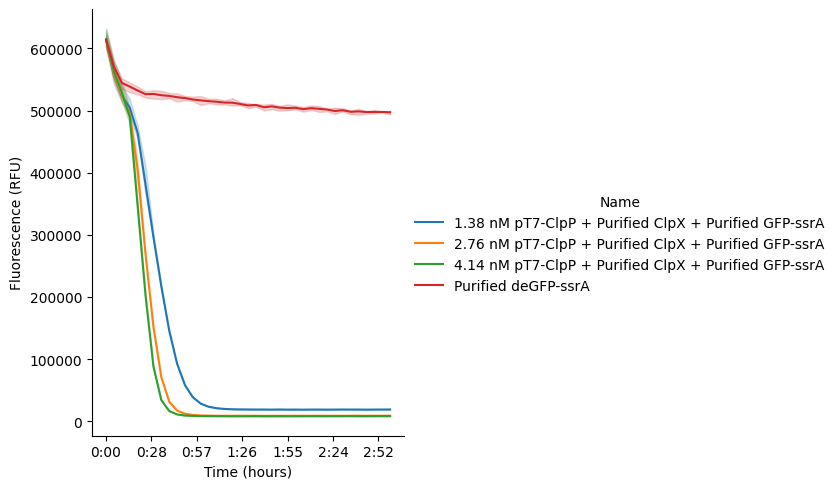

In [8]:
#| label: 20260604-clpp
#g = data.plot(style='Type')
g = data.plot()
g.savefig('raw', dpi=300)

## Normalize Data

In [14]:
data = data.normalize('Purified deGFP-ssrA')

Now replot your curves to see them normalized

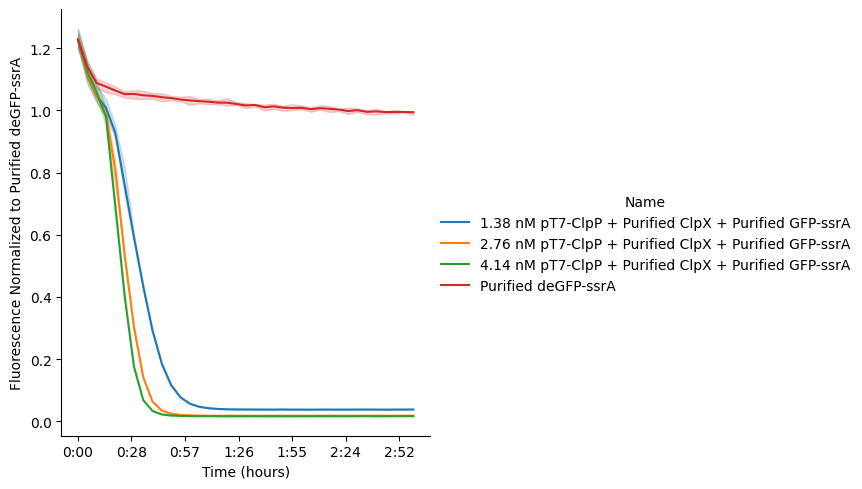

In [18]:
g = data.plot()
g.savefig('normalized-to-purified-degfp.png', dpi=300)

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants